# 📝 Assignment: Explainable AI for Text — LIME, SHAP & Integrated Gradients

**Dataset:** Emotion (dair-ai/emotion) — 20,000 English tweets labelled with **6 emotions**: sadness 😢, joy 😀, love ❤️, anger 😠, fear 😨, surprise 😲
**Model:** `bhadresh-savani/distilbert-base-uncased-emotion` (pre-trained, ~93% accuracy)

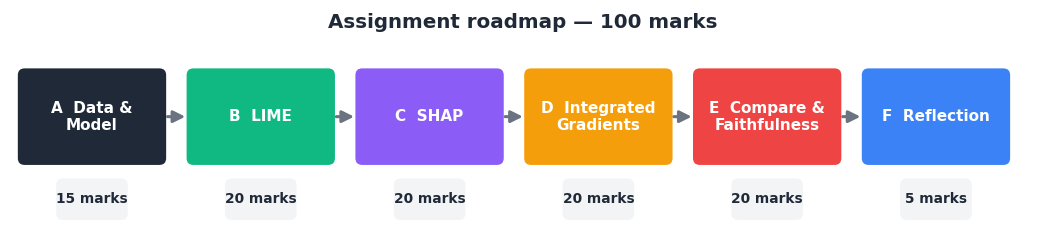

### 📋 Instructions
| | |
|---|---|
| ✏️ **Code cells marked `YOUR CODE HERE`** | Write your solution there. Everything else is given — just run it. |
| ✅ **Check cells** (`run_checks(...)`) | Run them after each task. They test your code and show ✅ / ❌. **Do not edit them.** |
| ✍️ **Answer cells** | Double-click and write 2–4 sentences. Use evidence from *your* outputs. |
| 🔑 **Hints** | Click to open — using them costs no marks. |
| 📤 **Submit** | `Runtime → Restart and run all`, then download as `RollNo_Name_XAI.ipynb`. |

<div style="background:#fffbeb;border-left:5px solid #F59E0B;padding:10px 14px;border-radius:6px;color:#111">⚠️ <b>New in this assignment:</b> the demo lab had 2 classes. Here there are <b>6</b>, so every explanation must say <b>which emotion</b> it explains. A word can support <i>fear</i> and argue against <i>joy</i> at the same time.</div>

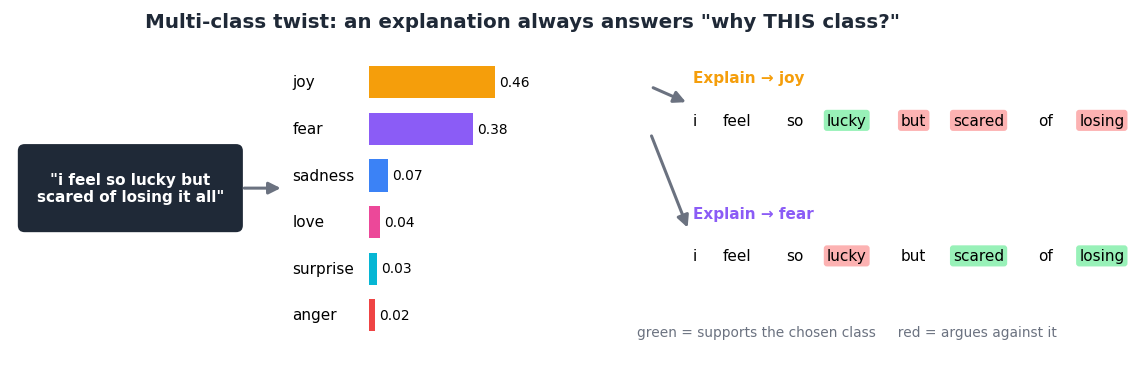

## ⚙️ Setup (given — just run)
Colab: `Runtime → Change runtime type → T4 GPU`.

In [1]:
!pip install -q transformers datasets lime shap captum ipywidgets plotly

In [2]:
import re, time, random, warnings, html as _html
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch
import plotly.express as px, plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- auto-checker (do not edit) ----------------
CHECKS = {}
def register(qid, *tests): CHECKS[qid] = tests

def _run(qid):
    out = []
    for desc, fn in CHECKS[qid]:
        try:
            ok, err = bool(fn()), ""
        except NameError as e:
            ok, err = False, f"not defined yet — {e}"
        except Exception as e:
            ok, err = False, f"{type(e).__name__}: {str(e)[:90]}"
        out.append((desc, ok, err))
    return out

def run_checks(qid):
    res = _run(qid); n = sum(ok for _, ok, _ in res)
    rows = "".join(f"<tr><td>{'✅' if ok else '❌'}</td><td>{_html.escape(d)}</td>"
                   f"<td style='color:#b91c1c;font-size:12px'>{_html.escape(e)}</td></tr>" for d, ok, e in res)
    col = "#10B981" if n == len(res) else "#F59E0B"
    display(HTML(f"<div style='border:2px solid {col};border-radius:8px;padding:8px 12px;background:#fff;color:#111'>"
                 f"<b style='color:{col}'>{qid}: {n}/{len(res)} checks passed {'🎉' if n == len(res) else ''}</b>"
                 f"<table style='margin-top:4px'>{rows}</table></div>"))

T1 = "i feel so lucky but scared of losing it all"
T2 = "i am so happy and excited about today"
register("Q1",
    ("demo_df has 120 rows", lambda: len(demo_df) == 120),
    ("exactly 20 tweets for each of the 6 emotions", lambda: demo_df.label.value_counts().eq(20).all() and demo_df.label.nunique() == 6),
    ("every tweet has 8–30 words", lambda: demo_df.n_words.between(8, 30).all()),
    ("rows are shuffled (first 12 rows not one class)", lambda: demo_df.label[:12].nunique() > 1),
    ("index reset to 0..119", lambda: list(demo_df.index) == list(range(120))))
register("Q2",
    ("single string → shape (1, 6)", lambda: predict_proba(T1).shape == (1, 6)),
    ("list of 3 strings → shape (3, 6)", lambda: predict_proba([T1, T2, T1]).shape == (3, 6)),
    ("every row sums to 1", lambda: np.allclose(predict_proba([T1, T2]).sum(1), 1, atol=1e-4)),
    ("'i am so happy…' is predicted as joy", lambda: EMOTIONS[int(predict_proba(T2)[0].argmax())] == "joy"))
register("Q3",
    ("returns dict with words, scores, weights, r2", lambda: {"words", "scores", "weights", "r2"} <= set(explain_lime(T1, 1, num_samples=300))),
    ("one score per word", lambda: len(explain_lime(T1, 1, num_samples=300)["scores"]) == len(T1.split())),
    ("some scores are non-zero", lambda: np.abs(explain_lime(T1, 1, num_samples=300)["scores"]).sum() > 0),
    ("same seed → same explanation", lambda: np.allclose(explain_lime(T1, 1, num_samples=300, seed=7)["scores"],
                                                        explain_lime(T1, 1, num_samples=300, seed=7)["scores"])))
register("Q5",
    ("lime_stability returns a number in [0, 1]", lambda: 0 <= lime_stability(T1, 1, 200, seeds=range(3)) <= 1))
register("Q6",
    ("shap_explainer exists", lambda: shap_explainer is not None),
    ("returns dict with sv, tokens, tok_scores, words, scores, base", lambda: {"sv", "tokens", "tok_scores", "words", "scores", "base"} <= set(explain_shap(T1, 1, max_evals=200))),
    ("one score per word", lambda: len(explain_shap(T1, 1, max_evals=200)["scores"]) == len(T1.split())),
    ("additivity: base + Σφ ≈ f(x)  (±0.02)", lambda: (lambda r: abs(r["base"] + r["tok_scores"].sum() - predict_proba(T1)[0, 1]) < 0.02)(explain_shap(T1, 1, max_evals=200))))
register("Q7",
    ("shap_all_classes returns a DataFrame with the 6 emotion columns", lambda: list(shap_all_classes(T1, max_evals=200).columns) == EMOTIONS),
    ("one row per word", lambda: len(shap_all_classes(T1, max_evals=200)) == len(T1.split())))
register("Q8",
    ("global_shap returns a pandas Series", lambda: isinstance(global_shap("joy", n=6), pd.Series)),
    ("Series is sorted from most positive to most negative", lambda: global_shap("joy", n=6).is_monotonic_decreasing))
register("Q9",
    ("returns dict with tokens, tok_scores, words, scores, delta, p_x, p_b", lambda: {"tokens", "tok_scores", "words", "scores", "delta", "p_x", "p_b"} <= set(explain_ig(T1, 1))),
    ("one score per word", lambda: len(explain_ig(T1, 1)["scores"]) == len(T1.split())),
    ("completeness: Σ IG ≈ F(x) − F(x′)  (±0.05, n_steps=100)", lambda: (lambda r: abs(r["tok_scores"].sum() - (r["p_x"] - r["p_b"])) < 0.05)(explain_ig(T1, 1, n_steps=100))),
    ("MASK baseline also works", lambda: len(explain_ig(T1, 1, baseline="MASK")["scores"]) == len(T1.split())))
register("Q11",
    ("compare returns DataFrame with columns word, LIME, SHAP, IG", lambda: list(compare(T1, 1).columns) == ["word", "LIME", "SHAP", "IG"]),
    ("one row per word", lambda: len(compare(T1, 1)) == len(T1.split())))
register("Q12",
    ("aopc returns a float", lambda: isinstance(aopc(T1, np.arange(len(T1.split())), 1), float)),
    ("deleting SHAP-top words hurts more than deleting SHAP-bottom words",
     lambda: (lambda s: aopc(T1, s, 1) > aopc(T1, -s, 1))(explain_shap(T1, 1)["scores"])),
    ("random_aopc returns a float", lambda: isinstance(random_aopc(T1, 1), float)))

def scorecard():
    rows = []
    for q in CHECKS:
        r = _run(q); rows.append((q, sum(ok for _, ok, _ in r), len(r)))
    html = "".join(f"<tr><td><b>{q}</b></td><td>{'🟩' * p}{'⬜' * (t - p)}</td><td>{p}/{t}</td></tr>" for q, p, t in rows)
    display(HTML(f"<table style='color:#111;background:#fff'>{html}</table>"))

print(f"✅ Setup done | device = {device}")

✅ Setup done | device = cpu


---
# Part A — Data & Model *(15 marks)*

## A.1 Load the dataset (given)

In [3]:
from datasets import load_dataset

ds = load_dataset("dair-ai/emotion", split="test")
EMOTIONS = ds.features["label"].names           # ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
df = ds.to_pandas()
df["emotion"] = df["label"].map(dict(enumerate(EMOTIONS)))
df["n_words"] = df["text"].str.split().str.len()
print(len(df), "tweets | classes:", EMOTIONS)
df.sample(5, random_state=SEED)

2000 tweets | classes: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


,text,label,emotion,n_words
1860,i feel so dirty but after spending a day at th...,0,sadness,51
353,i could feel his breath on me and smell the sw...,1,joy,14
1333,i just want to feel loved by you,2,love,8
905,i have felt the need to write out my sometimes...,3,anger,27
1289,at a party i met a girl who drew me to her,3,anger,12


### Q1 *(5 marks)* — Explore & build the demo set
Write code that:
1. Draws a **bar chart** of the number of tweets per emotion (Plotly). Is the dataset balanced?
2. Prints the **average number of words** per emotion.
3. Creates **`demo_df`**: exactly **20 tweets per emotion** with **8–30 words**, sampled with `random_state=SEED`, then **shuffled** (`random_state=SEED`) and with the **index reset**. → 120 rows.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Filter with <code>df.n_words.between(8, 30)</code>, sample each class with a list comprehension, join with <code>pd.concat</code>, then <code>.sample(frac=1, random_state=SEED).reset_index(drop=True)</code>.
</details>

In [4]:
# ✏️ Q1 — YOUR CODE HERE
# (a) tweets per emotion
counts = df.emotion.value_counts().reindex(EMOTIONS)
px.bar(x=counts.index, y=counts.values, color=counts.index, text=counts.values,
       labels={"x": "emotion", "y": "# tweets"}, title="Tweets per emotion (test split)").update_layout(height=330, showlegend=False).show()
print(counts.to_string(), "\n")

# (b) average words per emotion
print("Average number of words per emotion:")
print(df.groupby("emotion").n_words.mean().reindex(EMOTIONS).round(2).to_string())

# (c) demo set: 20 tweets x 6 emotions, 8-30 words, shuffled, index reset
ok = df[df.n_words.between(8, 30)]
demo_df = (pd.concat([ok[ok.label == c].sample(20, random_state=SEED) for c in range(6)])
             .sample(frac=1, random_state=SEED).reset_index(drop=True))
print("\ndemo_df:", demo_df.shape)
demo_df.head()

emotion
sadness     581
joy         695
love        159
anger       275
fear        224
surprise     66 

Average number of words per emotion:
emotion
sadness     19.04
joy         19.25
love        19.96
anger       19.44
fear        18.07
surprise    19.76

demo_df: (120, 4)


,text,label,emotion,n_words
0,i then feel your tender touch as you enfold me...,2,love,13
1,i cant write a review for a book i adore unles...,2,love,21
2,i feel if the pressure vessel has been serious...,0,sadness,19
3,i find myself in the odd position of feeling s...,2,love,11
4,i feel terrific in every one of them,1,joy,8


In [5]:
run_checks("Q1")

✅,demo_df has 120 rows,
✅,exactly 20 tweets for each of the 6 emotions,
✅,every tweet has 8–30 words,
✅,rows are shuffled (first 12 rows not one class),
✅,index reset to 0..119,


✍️ **Q1(d) — Your answer:** The dataset is **imbalanced**: joy has 695 test tweets and sadness 581, but anger 275, fear 224, love 159 and surprise only 66 (joy is ~10x surprise). Average length is almost identical across emotions (18.1–20.0 words), so length is not the issue, class frequency is. Accuracy can look high while rare classes such as surprise and love are handled badly, because they barely affect the total. So we should also look at per-class precision/recall/F1 (macro-F1) and not accuracy alone. (`demo_df` is balanced by design, 20 per class, so each emotion counts equally in our explanations.)

## A.2 Load the model (given)

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "bhadresh-savani/distilbert-base-uncased-emotion"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(device).eval()
print(model.config.id2label)
assert [model.config.id2label[i] for i in range(6)] == EMOTIONS, "label order mismatch!"
print("✅ model label order matches the dataset")

{0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}
✅ model label order matches the dataset


### Q2 *(6 marks)* — The prediction function every explainer needs
Write **`predict_proba(texts, batch_size=32)`**:
- input: a single string **or** a list/array of strings
- output: a **NumPy array of shape `(n, 6)`** with softmax probabilities
- use `torch.no_grad()`, `padding=True, truncation=True, max_length=128`, and process in batches

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Same pattern as the demo lab: <code>tokenizer(batch, padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)</code> → <code>model(**enc).logits</code> → <code>torch.softmax(..., dim=-1)</code>. Convert with <code>.cpu().numpy()</code> and <code>np.vstack</code> the batches. LIME/SHAP may pass a NumPy array — convert each item with <code>str()</code>.
</details>

In [7]:
# ✏️ Q2 — YOUR CODE HERE
@torch.no_grad()
def predict_proba(texts, batch_size=32):
    """string or list/array of strings -> numpy array (n, 6) of softmax probabilities"""
    if isinstance(texts, str):
        texts = [texts]
    texts = [str(t) for t in texts]
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=128, return_tensors="pt").to(device)
        out.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(out)

In [8]:
run_checks("Q2")

✅,"single string → shape (1, 6)",
✅,"list of 3 strings → shape (3, 6)",
✅,every row sums to 1,
✅,'i am so happy…' is predicted as joy,


### Model evaluation on `demo_df` (given)

In [9]:
from sklearn.metrics import confusion_matrix, classification_report
P = predict_proba(demo_df.text.tolist())          # (120, 6) — used later!
demo_df["pred"] = P.argmax(1)
cm = confusion_matrix(demo_df.label, demo_df.pred, labels=range(6))
px.imshow(cm, x=EMOTIONS, y=EMOTIONS, text_auto=True, color_continuous_scale="Blues",
          labels=dict(x="predicted", y="true"), title=f"Accuracy {np.mean(demo_df.pred == demo_df.label):.1%}").show()
print(classification_report(demo_df.label, demo_df.pred, target_names=EMOTIONS, digits=2))

              precision    recall  f1-score   support

     sadness       0.86      0.95      0.90        20
         joy       0.83      0.95      0.88        20
        love       0.95      0.95      0.95        20
       anger       0.93      0.70      0.80        20
        fear       0.72      0.90      0.80        20
    surprise       0.93      0.70      0.80        20

    accuracy                           0.86       120
   macro avg       0.87      0.86      0.86       120
weighted avg       0.87      0.86      0.86       120



In [10]:
# most frequent confusions (off-diagonal of the matrix above)
cm2 = cm.copy(); np.fill_diagonal(cm2, 0)
for i, j in zip(*np.unravel_index(np.argsort(-cm2, axis=None)[:4], cm2.shape)):
    print(f"true {EMOTIONS[i]:>8} -> predicted {EMOTIONS[j]:<8}: {cm2[i, j]}")

true surprise -> predicted fear    : 4
true    anger -> predicted sadness : 3
true surprise -> predicted joy     : 2
true    anger -> predicted fear    : 2


✍️ **Q2(b) — Your answer:** Overall accuracy on `demo_df` is 86%. The most frequent confusion is **surprise → fear (4 tweets)**, followed by **anger → sadness (3)**; surprise → joy and anger → fear (2 each) follow. This is also visible in the recall: anger and surprise have recall 0.70, the lowest of all classes. A likely reason is that these emotions share vocabulary and context. A surprised tweet ("strange", "weird", "shocked") often describes an uneasy feeling that reads as fear, and anger is often expressed together with hurt or frustration that looks like sadness. Surprise is also the rarest class in the training data (66 test tweets), so the model has seen fewer clean examples of it.

### 🧰 Helpers (given — run once)
All explainers below must return **one score per whitespace word** (`text.split()`), measured as contribution to **P(chosen emotion)**. These helpers draw and align them.

In [11]:
EMO_EMOJI = dict(sadness="😢", joy="😀", love="❤️", anger="😠", fear="😨", surprise="😲")

def highlight(words, scores, title="", note=""):
    scores = np.asarray(scores, float); m = np.abs(scores).max() or 1.0
    spans = "".join(f"<span title='{s:+.4f}' style='background:rgba({'16,185,129' if s > 0 else '239,68,68'},"
                    f"{min(1, abs(s) / m) * .85:.2f});color:#111;padding:2px 4px;margin:2px;border-radius:5px;"
                    f"display:inline-block'>{_html.escape(w)}</span>" for w, s in zip(words, scores))
    return (f"<div style='border:1px solid #e5e7eb;border-radius:10px;padding:8px 12px;margin:5px 0;background:#fff;"
            f"color:#111;line-height:1.9'><b>{title}</b> <span style='color:#666;font-size:12px'>{note}</span><br>{spans}</div>")

def prob_bars(p):
    fig = px.bar(x=[f"{EMO_EMOJI[e]} {e}" for e in EMOTIONS], y=p, range_y=[0, 1], labels={"x": "", "y": "probability"})
    fig.update_layout(height=250, margin=dict(t=20, b=20)); return fig

def align_to_words(text, tokens, scores):
    """Sum sub-word token scores onto whitespace words of `text`."""
    spans = [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]
    low, cur, out = text.lower(), 0, np.zeros(len(spans))
    for tok, s in zip(tokens, scores):
        t = str(tok).replace("##", "").strip().lower()
        if not t or t in {"[cls]", "[sep]", "[pad]", "[unk]", "[mask]"}: continue
        pos = low.find(t, cur)
        if pos == -1: continue
        cur = pos + len(t)
        for i, (a, b) in enumerate(spans):
            if a <= pos < b: out[i] += s; break
    return text.split(), out

CACHE = {}
def cached(method, text, **kw):
    """cached("LIME"|"SHAP"|"IG", text, label=..., ...) → runs explain_<method> once, adds 'time'."""
    key = (method, text, tuple(sorted(kw.items())))
    if key not in CACHE:
        t0 = time.time(); r = globals()[f"explain_{method.lower()}"](text, **kw)
        r["time"] = time.time() - t0; CACHE[key] = r
    return CACHE[key]

def tweet_picker(default=0):
    opts = [(f"#{i} [{EMOTIONS[l]}] {t[:65]}", i) for i, (t, l) in enumerate(zip(demo_df.text, demo_df.label))]
    dd = widgets.Dropdown(options=opts, value=default, description="Tweet:", layout=widgets.Layout(width="95%"))
    ta = widgets.Textarea(value=demo_df.text[default], layout=widgets.Layout(width="95%", height="60px"))
    dd.observe(lambda ch: setattr(ta, "value", demo_df.text[ch["new"]]), names="value")
    return dd, ta
print("✅ helpers ready")

✅ helpers ready


---
# Part B — LIME *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> LIME removes random words, queries the model, and fits a weighted linear model. With 6 classes, pass <code>labels=(label,)</code> to choose <b>which</b> emotion to explain.</div>

### Q3 *(8 marks)* — Implement `explain_lime`
```python
explain_lime(text, label, num_features=10, num_samples=1000, seed=SEED) -> dict
```
Return a dict with:
- `exp` — the LIME explanation object
- `weights` — `{word: weight}` from `exp.as_list(label=label)`
- `words` — `text.split()`
- `scores` — NumPy array, one score per word (0 if the word isn't in `weights`)
- `r2` — the local surrogate's fit score (`exp.score`)

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Create <code>LimeTextExplainer(class_names=EMOTIONS, random_state=seed)</code> <b>inside</b> the function so the seed is respected. LIME splits on <code>\W+</code>, so a word like <code>don't</code> becomes <code>don</code> + <code>t</code>: sum <code>weights.get(piece, 0)</code> over <code>re.split(r'\W+', word)</code>.
</details>

In [12]:
# ✏️ Q3 — YOUR CODE HERE
from lime.lime_text import LimeTextExplainer

def explain_lime(text, label, num_features=10, num_samples=1000, seed=SEED):
    explainer = LimeTextExplainer(class_names=EMOTIONS, random_state=seed)   # inside -> seed is respected
    exp = explainer.explain_instance(text, predict_proba, num_features=num_features,
                                     num_samples=num_samples, labels=(label,))
    weights = dict(exp.as_list(label=label))                  # {word: weight toward `label`}
    words = text.split()
    # LIME splits on \W+, so "don't" -> "don" + "t": sum the weights of the pieces
    scores = np.array([sum(weights.get(p, 0.0) for p in re.split(r"\W+", w) if p) for w in words])
    r2 = exp.score[label] if isinstance(exp.score, dict) else exp.score   # local surrogate fit
    return dict(exp=exp, words=words, scores=scores, weights=weights, r2=float(r2))

In [13]:
run_checks("Q3")

✅,"returns dict with words, scores, weights, r2",
✅,one score per word,
✅,some scores are non-zero,
✅,same seed → same explanation,


### Q4 *(6 marks)* — Explaining an ambiguous tweet
1. Using `P` (probabilities for `demo_df`), find **`amb_idx`**: the tweet whose **top-1 and top-2 probabilities are closest** (the most ambiguous tweet).
2. Show its probabilities with `prob_bars(...)`.
3. Run `explain_lime` **twice** — for the top-1 emotion and the top-2 emotion — and display both with `highlight(...)`.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>S = np.sort(P, axis=1)</code> → gap = <code>S[:, -1] - S[:, -2]</code> → <code>amb_idx = int(np.argmin(gap))</code>. Top-2 labels: <code>np.argsort(-P[amb_idx])[:2]</code>.
</details>

In [14]:
# ✏️ Q4 — YOUR CODE HERE
# 1. most ambiguous tweet = smallest gap between top-1 and top-2 probability
S = np.sort(P, axis=1)
gap = S[:, -1] - S[:, -2]
amb_idx = int(np.argmin(gap))
amb_text = demo_df.text[amb_idx]
top1, top2 = [int(c) for c in np.argsort(-P[amb_idx])[:2]]
print(f"Tweet #{amb_idx} (true label: {EMOTIONS[demo_df.label[amb_idx]]}): {amb_text!r}")
print(f"top-1 = {EMOTIONS[top1]} ({P[amb_idx, top1]:.3f}) | top-2 = {EMOTIONS[top2]} ({P[amb_idx, top2]:.3f}) | gap = {gap[amb_idx]:.4f}")

# 2. probabilities
prob_bars(P[amb_idx]).show()

# 3. LIME for both emotions
for lab in (top1, top2):
    r = explain_lime(amb_text, lab, num_features=len(amb_text.split()), num_samples=1000)
    display(HTML(highlight(r["words"], r["scores"], f"LIME → {EMO_EMOJI[EMOTIONS[lab]]} {EMOTIONS[lab]}", f"R² = {r['r2']:.2f}")))
    print(EMOTIONS[lab], "->", {str(w): round(float(v), 3) for w, v in sorted(r["weights"].items(), key=lambda kv: -abs(kv[1]))[:6]})

Tweet #15 (true label: fear): 'i become someone else and i make random awkward jokes honestly this feeling is so strange is this what it feels like to be on top of a cloud'
top-1 = fear (0.498) | top-2 = surprise (0.494) | gap = 0.0039


fear -> {'strange': 0.566, 'is': -0.108, 'feeling': -0.066, 'jokes': -0.059, 'i': -0.039, 'cloud': 0.028}


surprise -> {'strange': 0.391, 'is': 0.104, 'feeling': 0.066, 'jokes': 0.057, 'i': 0.038, 'feels': -0.026}


✍️ **Q4(d) — Your answer:** The ambiguous tweet is #15 ("…this feeling is so strange is this what it feels like to be on top of a cloud"), with fear 0.498 vs surprise 0.494 (gap 0.004). In LIME the word **"is"** has weight **−0.108 for fear** but **+0.104 for surprise**; "feeling" shows the same flip (−0.066 vs +0.066). In the SHAP heat-map, **"jokes"** is −0.119 for fear but +0.062 for surprise. Only "strange" supports both emotions (+0.566 fear, +0.391 surprise), which is exactly why the model cannot decide. So in a multi-class problem an explanation is only meaningful *relative to a chosen class*: the same word can push towards one emotion and away from another, and an explanation for the predicted class alone hides the competing evidence.

### Q5 *(6 marks)* — How stable is LIME?
Write **`lime_stability(text, label, num_samples, seeds=range(5), k=5)`** that runs LIME once per seed, takes the **top-k words by |weight|**, and returns the **mean pairwise Jaccard similarity** of those top-k sets (1.0 = identical every time).

Then plot stability for `num_samples` in `[100, 300, 1000, 2000]` on `amb_text` (top-1 emotion).

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Jaccard(A, B) = |A ∩ B| / |A ∪ B|. Use <code>itertools.combinations(sets, 2)</code> for the pairs. Top-k: <code>sorted(r['weights'], key=lambda w: -abs(r['weights'][w]))[:k]</code>.
</details>

In [15]:
# ✏️ Q5 — YOUR CODE HERE
from itertools import combinations

def lime_stability(text, label, num_samples, seeds=range(5), k=5):
    """mean pairwise Jaccard similarity of the top-k LIME words across seeds (1.0 = identical)"""
    sets = []
    for s in seeds:
        w = explain_lime(text, label, num_features=k, num_samples=num_samples, seed=s)["weights"]
        sets.append(set(sorted(w, key=lambda x: -abs(w[x]))[:k]))
    jac = [len(a & b) / len(a | b) for a, b in combinations(sets, 2) if len(a | b)]
    return float(np.mean(jac)) if jac else 1.0

ns_list = [100, 300, 1000, 2000]
stab = [lime_stability(amb_text, top1, n, k=5) for n in ns_list]
for n, s_ in zip(ns_list, stab): print(f"num_samples = {n:>4}  ->  stability (Jaccard) = {s_:.3f}")
px.line(x=ns_list, y=stab, markers=True, log_x=True, range_y=[0, 1.05],
        labels={"x": "num_samples (log)", "y": "mean pairwise Jaccard of top-5 words"},
        title=f"LIME stability for '{EMOTIONS[top1]}' on the ambiguous tweet").update_layout(height=330).show()

num_samples =  100  ->  stability (Jaccard) = 0.414
num_samples =  300  ->  stability (Jaccard) = 0.700
num_samples = 1000  ->  stability (Jaccard) = 1.000
num_samples = 2000  ->  stability (Jaccard) = 1.000


In [16]:
run_checks("Q5")

✅,"lime_stability returns a number in [0, 1]",


✍️ **Q5(b) — Your answer:** Stability (mean pairwise Jaccard of the top-5 words over 5 seeds) rises with the number of samples: **0.41 at 100, 0.70 at 300, 1.00 at 1000 and 1.00 at 2000**. With few perturbations the linear surrogate is fitted on a small random sample, so different seeds pick different words; with more samples the fit converges and the explanation stops depending on the seed. I would recommend **num_samples ≈ 1000**: it is already fully stable here, and 2000 only doubles the runtime without any gain. (For longer texts with more words, more samples would be needed.)

---
# Part C — SHAP *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> SHAP values are fair (Shapley) shares of the prediction. <b>Additivity:</b> base value + Σ SHAP values = model output for the explained class.</div>

### Q6 *(8 marks)* — Implement `explain_shap`
1. Create a global **`shap_explainer`** = `shap.Explainer(predict_proba, shap.maskers.Text(tokenizer), output_names=EMOTIONS)`.
2. Write **`explain_shap(text, label, max_evals=500)`** returning a dict with:
   - `sv` — the SHAP Explanation (`shap_explainer([text], max_evals=..., silent=True)`)
   - `tokens` — `list(sv.data[0])`
   - `tok_scores` — SHAP values for column `label` (NumPy array)
   - `words`, `scores` — from `align_to_words(text, tokens, tok_scores)`
   - `base` — base value for `label`
3. Show `shap.plots.text(...)` for `amb_text` and its top-1 emotion.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>sv.values[0]</code> has shape <code>(n_tokens, 6)</code> → take <code>[:, label]</code>. <code>sv.base_values[0][label]</code> is the base. Plot: <code>shap.plots.text(r['sv'][0, :, label])</code>.
</details>

In [17]:
# ✏️ Q6 — YOUR CODE HERE
import shap

shap_explainer = shap.Explainer(predict_proba, shap.maskers.Text(tokenizer), output_names=EMOTIONS)

def explain_shap(text, label, max_evals=500):
    sv = shap_explainer([text], max_evals=max_evals, silent=True)
    tokens = list(sv.data[0])
    tok_scores = np.array(sv.values[0])[:, label]              # contribution to P(label)
    words, scores = align_to_words(text, tokens, tok_scores)
    base = float(np.array(sv.base_values[0])[label])
    return dict(sv=sv, tokens=tokens, tok_scores=tok_scores, words=words, scores=scores, base=base)

r_shap = explain_shap(amb_text, top1)
print(f"SHAP for '{EMOTIONS[top1]}': base {r_shap['base']:.3f} + sum(phi) {r_shap['tok_scores'].sum():+.3f} "
      f"= {r_shap['base'] + r_shap['tok_scores'].sum():.3f}  vs  f(x) = {predict_proba(amb_text)[0, top1]:.3f}")
shap.plots.text(r_shap["sv"][0, :, top1])

SHAP for 'fear': base 0.141 + sum(phi) +0.357 = 0.498  vs  f(x) = 0.498


In [18]:
run_checks("Q6")

✅,shap_explainer exists,
✅,"returns dict with sv, tokens, tok_scores, words, scores, base",
✅,one score per word,
✅,additivity: base + Σφ ≈ f(x) (±0.02),


### Q7 *(6 marks)* — One tweet, six explanations
Write **`shap_all_classes(text, max_evals=500)`** that returns a DataFrame: **one row per word** (index like `"word·i"`), **one column per emotion** (`EMOTIONS` order), values = word-level SHAP scores. Call SHAP **only once** (one call already returns all 6 classes).

Draw it as a heat-map (`px.imshow`, diverging colours, midpoint 0) for `amb_text`.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Loop <code>for c in range(6)</code> over <code>np.array(sv.values[0])[:, c]</code> and align each column with <code>align_to_words</code>.
</details>

In [19]:
# ✏️ Q7 — YOUR CODE HERE
def shap_all_classes(text, max_evals=500):
    sv = shap_explainer([text], max_evals=max_evals, silent=True)      # ONE call -> all 6 classes
    tokens, vals = list(sv.data[0]), np.array(sv.values[0])
    cols = {}
    for c in range(6):
        words, cols[EMOTIONS[c]] = align_to_words(text, tokens, vals[:, c])
    return pd.DataFrame(cols, index=[f"{w}·{i}" for i, w in enumerate(words)])[EMOTIONS]

heat = shap_all_classes(amb_text)
px.imshow(heat, color_continuous_scale="RdBu", color_continuous_midpoint=0, text_auto=".2f", aspect="auto",
          title="Word-level SHAP for each emotion (ambiguous tweet)").update_layout(height=120 + 30 * len(heat)).show()
heat.round(3)

,sadness,joy,love,anger,fear,surprise
i·0,0.014,0.018,-0.003,-0.003,-0.026,-0.000
become·1,0.003,-0.002,-0.003,-0.001,0.004,-0.001
someone·2,-0.001,-0.012,-0.003,-0.001,0.017,-0.000
else·3,-0.009,-0.009,-0.000,0.004,0.012,0.002
and·4,-0.026,-0.002,0.001,0.009,0.013,0.004
i·5,0.011,0.006,-0.002,-0.003,-0.010,-0.002
make·6,0.019,0.002,-0.003,-0.000,-0.016,-0.002
random·7,-0.084,-0.011,-0.005,0.007,0.090,0.003
awkward·8,0.265,-0.139,-0.012,-0.018,-0.085,-0.011
jokes·9,0.014,0.029,-0.001,0.015,-0.119,0.062


In [20]:
run_checks("Q7")

✅,shap_all_classes returns a DataFrame with the 6 emotion columns,
✅,one row per word,


### Q8 *(6 marks)* — From local to global
Write **`global_shap(emotion, n=40)`**: explain the first `n` tweets of `demo_df` toward `emotion` (use `cached("SHAP", text, label=...)`), clean each word (`re.sub(r"\W", "", w.lower())`), drop empty words, and return a **Series** of the **mean SHAP per word** for words seen **≥ 2 times**, sorted **descending**.

Then run the given 🎮 explorer below.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Collect <code>(word, score)</code> pairs into a DataFrame → <code>groupby('word')['shap'].agg(['mean', 'count'])</code> → filter <code>count >= 2</code> → <code>['mean'].sort_values(ascending=False)</code>.
</details>

In [21]:
# ✏️ Q8 — YOUR CODE HERE
def global_shap(emotion, n=40):
    lab = EMOTIONS.index(emotion)
    rows = []
    for text in demo_df.text[:n]:
        r = cached("SHAP", text, label=lab)
        rows += [(re.sub(r"\W", "", w.lower()), s) for w, s in zip(r["words"], r["scores"])]
    g = pd.DataFrame(rows, columns=["word", "shap"]).query("word != ''")
    g = g.groupby("word")["shap"].agg(["mean", "count"]).query("count >= 2")
    return g["mean"].sort_values(ascending=False)

# quick look at the strongest words for two emotions (used in the written answer)
for e in ["anger", "joy"]:
    s_ = global_shap(e, 40)
    print(e, "-> top:", [(w, round(v, 3)) for w, v in s_.head(5).items()], "| bottom:", [(w, round(v, 3)) for w, v in s_.tail(3).items()])

anger -> top: [('stressed', 0.401), ('been', 0.018), ('done', 0.017), ('not', 0.015), ('would', 0.015)] | bottom: [('impressed', -0.103), ('feeling', -0.109), ('entertained', -0.139)]


joy -> top: [('entertained', 0.406), ('advanced', 0.238), ('feel', 0.133), ('feeling', 0.088), ('feels', 0.082)] | bottom: [('stressed', -0.4), ('impressed', -0.422), ('repressed', -0.593)]


In [22]:
run_checks("Q8")

✅,global_shap returns a pandas Series,
✅,Series is sorted from most positive to most negative,


In [23]:
# 🎮 Global explorer (given) — uses YOUR global_shap
emo = widgets.Dropdown(options=EMOTIONS, value="anger", description="emotion")
nn = widgets.IntSlider(40, 10, 120, step=10, description="# tweets")
b, o = widgets.Button(description="Explore ▶", button_style="info"), widgets.Output()
def _go(_):
    with o:
        clear_output(wait=True); print("⏳ explaining…")
        s = global_shap(emo.value, nn.value); top = pd.concat([s.head(10), s.tail(10)]).sort_values()
        clear_output(wait=True)
        px.bar(x=top.values, y=top.index, orientation="h", color=top.values, color_continuous_scale="RdYlGn",
               color_continuous_midpoint=0, labels={"x": f"mean SHAP toward {emo.value}", "y": ""},
               title=f"{EMO_EMOJI[emo.value]} Words that push toward / away from {emo.value}").update_layout(height=520).show()
b.on_click(_go); display(widgets.HBox([emo, nn, b]), o)

Output()

✍️ **Q8(b) — Your answer:** Over the first 40 tweets, the top words for **anger** are *stressed* (+0.401), *been* (+0.018), *done* (+0.017), and for **joy** they are *entertained* (+0.406), *advanced* (+0.238), *feel* (+0.133). Some are sensible (*stressed* for anger, *entertained* for joy), but the lists are dominated by a single keyword and the rest is weak or neutral (*been*, *done*, *feel*). The negative end suggests surface-form reliance: for joy the most negative words are *repressed* (−0.593), *impressed* (−0.422) and *stressed* (−0.400), words that share the "-pressed" ending, even though "impressed" is positive in meaning. This is a problem because a model that keys on individual words or word pieces can be fooled by negation, sarcasm or unseen words ("not entertained"), and it may encode spurious or biased associations that accuracy hides. (Words are only counted if seen ≥ 2 times in 40 tweets, so these averages are noisy.)

---
# Part D — Integrated Gradients *(20 marks)*

<div style="background:#ecfdf5;border-left:5px solid #10B981;padding:10px 14px;border-radius:6px;color:#111">💡 <b>Recall:</b> IGᵢ = (xᵢ − x′ᵢ) × ∫₀¹ ∂F(x′ + α(x − x′))/∂xᵢ dα. <b>Completeness:</b> Σ IG = F(x) − F(x′). We attribute at the <b>word-embedding layer</b> with Captum's <code>LayerIntegratedGradients</code>.</div>

### Q9 *(12 marks)* — Implement `explain_ig`
1. `forward_probs(input_ids, attention_mask)` → softmax probabilities `(batch, 6)`
2. `lig = LayerIntegratedGradients(forward_probs, model.distilbert.embeddings.word_embeddings)`
3. `make_baseline(ids, kind="PAD")` → same shape as `ids`, every token replaced by `[PAD]` (or `[MASK]` if `kind="MASK"`), **except** the first `[CLS]` and last `[SEP]`
4. `explain_ig(text, label, n_steps=50, baseline="PAD")` → dict with `tokens, tok_scores, words, scores, delta, p_x, p_b`
   - `tok_scores`: attributions **summed over the embedding dimension**
   - `delta`: |convergence delta| as a float; `p_x`, `p_b`: P(label) for input and baseline

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>lig.attribute(inputs=ids, baselines=base, additional_forward_args=(mask,), target=label, n_steps=n_steps, internal_batch_size=25, return_convergence_delta=True)</code> returns <code>(attrs, delta)</code>; <code>attrs</code> has shape <code>(1, seq_len, 768)</code>. Token strings: <code>tokenizer.convert_ids_to_tokens(ids[0].tolist())</code>. IDs: <code>tokenizer.pad_token_id</code>, <code>tokenizer.mask_token_id</code>.
</details>

In [24]:
# ✏️ Q9 — YOUR CODE HERE
from captum.attr import LayerIntegratedGradients

def forward_probs(input_ids, attention_mask):
    return torch.softmax(model(input_ids=input_ids, attention_mask=attention_mask).logits, dim=-1)

emb_layer = model.distilbert.embeddings.word_embeddings
lig = LayerIntegratedGradients(forward_probs, emb_layer)

def encode(text):
    enc = tokenizer(text, return_tensors="pt", truncation=True, max_length=128).to(device)
    return enc["input_ids"], enc["attention_mask"]

def make_baseline(ids, kind="PAD"):
    ref = tokenizer.pad_token_id if kind == "PAD" else tokenizer.mask_token_id
    base = torch.full_like(ids, ref)
    base[:, 0], base[:, -1] = ids[:, 0], ids[:, -1]            # keep [CLS] and [SEP]
    return base

def explain_ig(text, label, n_steps=50, baseline="PAD"):
    ids, mask = encode(text)
    base = make_baseline(ids, baseline)
    attrs, delta = lig.attribute(inputs=ids, baselines=base, additional_forward_args=(mask,), target=label,
                                 n_steps=n_steps, internal_batch_size=25, return_convergence_delta=True)
    tok_scores = attrs.sum(dim=-1)[0].detach().cpu().numpy()   # sum over the embedding dimension
    tokens = tokenizer.convert_ids_to_tokens(ids[0].tolist())
    with torch.no_grad():
        p_x = forward_probs(ids, mask)[0, label].item()
        p_b = forward_probs(base, mask)[0, label].item()
    words, scores = align_to_words(text, tokens, tok_scores)
    return dict(tokens=tokens, tok_scores=tok_scores, words=words, scores=scores,
                delta=abs(float(delta.item())), p_x=p_x, p_b=p_b)

In [25]:
run_checks("Q9")

✅,"returns dict with tokens, tok_scores, words, scores, delta, p_x, p_b",
✅,one score per word,
✅,"completeness: Σ IG ≈ F(x) − F(x′) (±0.05, n_steps=100)",
✅,MASK baseline also works,


### Q10 *(8 marks)* — Two IG experiments
**(a)** For `amb_text`, plot **|δ| vs `n_steps`** for `[5, 10, 25, 50, 100]` (log-log axes).
**(b)** For the first **10 tweets** of `demo_df` (each explained for its predicted emotion), compute the **Spearman correlation** between word scores using the **PAD** and the **MASK** baseline. Print the mean and draw a histogram/strip plot.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>spearmanr(a, b)[0]</code> gives ρ. Use <code>np.nanmean</code> in case a score vector is constant.
</details>

In [26]:
# ✏️ Q10 — YOUR CODE HERE
# (a) |delta| vs n_steps on the ambiguous tweet
steps = [5, 10, 25, 50, 100]
deltas = [explain_ig(amb_text, top1, n_steps=s)["delta"] for s in steps]
for s, d in zip(steps, deltas): print(f"n_steps = {s:>3}  |delta| = {d:.5f}")
px.line(x=steps, y=deltas, markers=True, log_x=True, log_y=True,
        labels={"x": "n_steps (log)", "y": "|convergence delta| (log)"},
        title="IG completeness error vs number of steps").update_layout(height=320).show()

# (b) PAD vs MASK baseline: Spearman correlation on the first 10 tweets (predicted emotion)
rhos = []
for i in range(10):
    t, lab = demo_df.text[i], int(demo_df.pred[i])
    a = explain_ig(t, lab, baseline="PAD")["scores"]
    b = explain_ig(t, lab, baseline="MASK")["scores"]
    rhos.append(spearmanr(a, b)[0])
print("Spearman rho per tweet:", np.round(rhos, 2))
print(f"Mean Spearman (PAD vs MASK) = {np.nanmean(rhos):.3f}")
px.strip(y=rhos, labels={"y": "Spearman rho (PAD vs MASK)"}, title="Does the baseline matter?").update_layout(height=320).show()

n_steps =   5  |delta| = 1.36680
n_steps =  10  |delta| = 2.49949
n_steps =  25  |delta| = 0.12870
n_steps =  50  |delta| = 0.06986
n_steps = 100  |delta| = 0.00192


Spearman rho per tweet: [ 0.84  0.58  0.69  0.37  0.62 -0.08  0.55  0.55  0.67  0.65]
Mean Spearman (PAD vs MASK) = 0.544


✍️ **Q10(c) — Your answer:** |δ| is large for very few steps (1.37 at 5 steps, 2.50 at 10, not even monotonic) and then drops quickly: 0.129 at 25, 0.070 at 50 and **0.0019 at 100**. So about **50 steps is a minimum and ~100 is enough** for the completeness error to be negligible (< 0.01); I would check δ rather than assume a number. The baseline clearly matters: the mean Spearman correlation between the PAD and MASK explanations over 10 tweets is only **0.54**, ranging from −0.08 to 0.84, so the two baselines often rank words differently. This is a weakness because there is no "correct" neutral input, so the explanation depends on an arbitrary choice; it can also be seen as a feature, because the baseline defines the question being asked ("what changed the prediction compared with *this* reference?") and can be chosen to fit the task.

---
# Part E — Comparison & Faithfulness *(20 marks)*

### 🎮 Your explainer dashboard (given — works once Q3, Q6, Q9 pass)
Pick any tweet (or type your own), a method and an emotion.

In [27]:
dd, ta = tweet_picker()
meth = widgets.ToggleButtons(options=["LIME", "SHAP", "IG"], description="method")
emo2 = widgets.Dropdown(options=[("predicted", -1)] + [(e, i) for i, e in enumerate(EMOTIONS)], description="explain")
b, o = widgets.Button(description="Explain ▶", button_style="success"), widgets.Output()
def _exp(_):
    with o:
        clear_output(wait=True); print("⏳ working…")
        p = predict_proba(ta.value)[0]; lab = int(p.argmax()) if emo2.value == -1 else emo2.value
        kw = {"num_features": len(ta.value.split())} if meth.value == "LIME" else {}
        r = cached(meth.value, ta.value, label=lab, **kw)
        clear_output(wait=True); prob_bars(p).show()
        display(HTML(highlight(r["words"], r["scores"], f"{meth.value} → {EMO_EMOJI[EMOTIONS[lab]]} {EMOTIONS[lab]}", f"{r['time']:.1f}s")))
b.on_click(_exp); display(dd, ta, widgets.HBox([meth, emo2]), b, o)

Dropdown(description='Tweet:', layout=Layout(width='95%'), options=(('#0 [love] i then feel your tender touch …

Textarea(value='i then feel your tender touch as you enfold me with his love', layout=Layout(height='60px', wi…

Button(button_style='success', description='Explain ▶', style=ButtonStyle())

Output()

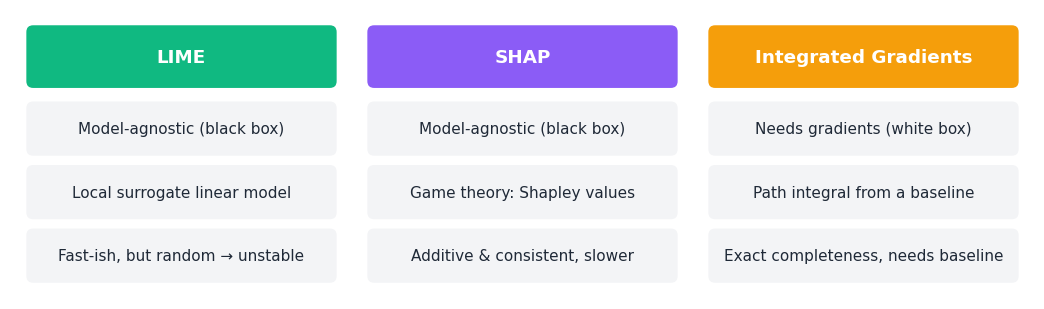

### Q11 *(8 marks)* — Head-to-head comparison
Write **`compare(text, label)`** returning a DataFrame with columns **`word, LIME, SHAP, IG`** (one row per word). Use `cached(...)`; for LIME pass `num_features=len(text.split())` so every word gets a score.

Then for `amb_text` (top-1 emotion):
1. Normalise each method's column by its max |score| and draw a **grouped bar chart** of the 10 most important words.
2. Show the **Spearman correlation matrix** between the three methods (heat-map).
3. Print the **top-3 words** of each method.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

<code>C[['LIME','SHAP','IG']].corr(method='spearman')</code>. Most important words: <code>norm.abs().max(axis=1).nlargest(10).index</code>.
</details>

In [28]:
# ✏️ Q11 — YOUR CODE HERE
def compare(text, label):
    n = len(text.split())
    l = cached("LIME", text, label=label, num_features=n)
    s = cached("SHAP", text, label=label)
    g = cached("IG", text, label=label)
    return pd.DataFrame({"word": l["words"], "LIME": l["scores"], "SHAP": s["scores"], "IG": g["scores"]})

cmp_df = compare(amb_text, top1)
norm = cmp_df[["LIME", "SHAP", "IG"]].apply(lambda col: col / max(1e-12, col.abs().max()))
norm.index = [f"{w}·{i}" for i, w in enumerate(cmp_df.word)]

# 1. grouped bar chart of the 10 most important words
top10 = norm.loc[norm.abs().max(axis=1).nlargest(10).index]
px.bar(top10, barmode="group", color_discrete_map={"LIME": "#10B981", "SHAP": "#8B5CF6", "IG": "#F59E0B"},
       labels={"value": "score / max |score|", "index": "word"},
       title=f"Normalised importance toward '{EMOTIONS[top1]}' (top 10 words)").update_layout(height=380).show()

# 2. Spearman correlation heat-map
corr = cmp_df[["LIME", "SHAP", "IG"]].corr(method="spearman")
px.imshow(corr, text_auto=".2f", color_continuous_scale="RdBu", zmin=-1, zmax=1,
          title="Spearman correlation between methods").update_layout(height=340, width=420).show()

# 3. top-3 words of each method
for m in ["LIME", "SHAP", "IG"]:
    print(f"{m:>4} top-3:", list(cmp_df.assign(a=cmp_df[m].abs()).nlargest(3, "a").word))

LIME top-3: ['strange', 'is', 'is']
SHAP top-3: ['strange', 'jokes', 'random']
  IG top-3: ['strange', 'so', 'jokes']


In [29]:
run_checks("Q11")

✅,"compare returns DataFrame with columns word, LIME, SHAP, IG",
✅,one row per word,


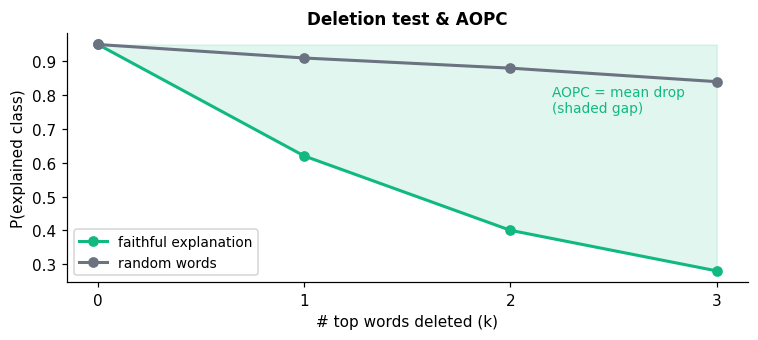

### Q12 *(12 marks)* — Which explanation is most faithful?
1. **`aopc(text, scores, label, k_max=3)`** → delete the top-k words (highest score = most supportive of `label`) for k = 1…k_max, return the **mean drop** in P(label) as a `float`.
2. **`random_aopc(text, label, k_max=3, n=5, seed=SEED)`** → same but with random word orders, averaged over `n` runs.
3. **Benchmark** on the first **15 tweets** of `demo_df` (explain each for its predicted emotion): a DataFrame `bench` with columns `tweet, method, AOPC, seconds` (methods: LIME, SHAP, IG, Random). Show the **mean table** and a **box plot** of AOPC.

<details><summary>🔑 <b>Hint</b> (click to open)</summary>

Order: <code>np.argsort(-np.asarray(scores))</code>. Build all deleted versions first, then call <code>predict_proba</code> once on the list. Use <code>min(k_max, len(words) - 1)</code> so a tweet never becomes empty. Random order: pass <code>rng.random(n_words)</code> as fake scores to <code>aopc</code>.
</details>

In [30]:
# ✏️ Q12 — YOUR CODE HERE
def aopc(text, scores, label, k_max=3):
    """mean drop in P(label) after deleting the top-k scoring words, k = 1..k_max"""
    words = text.split()
    k_max = min(k_max, len(words) - 1)
    order = np.argsort(-np.asarray(scores))
    texts = [text] + [" ".join(w for i, w in enumerate(words) if i not in set(order[:k].tolist()))
                      for k in range(1, k_max + 1)]
    p = predict_proba(texts)[:, label]
    return float(np.mean(p[0] - p[1:]))

def random_aopc(text, label, k_max=3, n=5, seed=SEED):
    rng = np.random.default_rng(seed)
    nw = len(text.split())
    return float(np.mean([aopc(text, rng.random(nw), label, k_max) for _ in range(n)]))

rows = []
for i in range(15):
    t, lab = demo_df.text[i], int(demo_df.pred[i])
    kw = {"LIME": {"num_features": len(t.split())}, "SHAP": {}, "IG": {}}
    for m in ["LIME", "SHAP", "IG"]:
        r = cached(m, t, label=lab, **kw[m])
        rows.append(dict(tweet=i, method=m, AOPC=aopc(t, r["scores"], lab), seconds=r["time"]))
    rows.append(dict(tweet=i, method="Random", AOPC=random_aopc(t, lab), seconds=0.0))
bench = pd.DataFrame(rows)

display(bench.groupby("method")[["AOPC", "seconds"]].mean().round(4).sort_values("AOPC", ascending=False))
px.box(bench, x="method", y="AOPC", color="method", points="all",
       color_discrete_map={"LIME": "#10B981", "SHAP": "#8B5CF6", "IG": "#F59E0B", "Random": "#9CA3AF"},
       title="Faithfulness (AOPC, higher = better) over 15 tweets").update_layout(height=380, showlegend=False).show()

,AOPC,seconds
method,,
LIME,0.7857,8.3618
SHAP,0.7553,4.1092
IG,0.7091,1.1848
Random,0.1018,0.0000


In [31]:
run_checks("Q12")

✅,aopc returns a float,
✅,deleting SHAP-top words hurts more than deleting SHAP-bottom words,
✅,random_aopc returns a float,


✍️ **Q12(d) — Your answer:** On 15 tweets the mean AOPC was **LIME 0.786 > SHAP 0.755 > IG 0.709**, all far above **Random 0.102**, so all three methods find words that really matter. Mean time per explanation was **IG 1.2 s < SHAP 4.1 s < LIME 8.4 s** (on CPU), the reverse order. The faithfulness gaps are small compared with the spread across tweets, so I would not call LIME clearly better; also LIME is trained on word-removal perturbations, which is exactly what the deletion test does, so it has a slight home advantage. (i) For a **real-time app** I would use **IG**: it is ~7x faster than LIME and still ~7x better than random, provided we have access to the model's gradients. (ii) For an **audit report** I would use **SHAP**: it has the additivity guarantee (base + Σφ = f(x), verified in Q6), is nearly as faithful as LIME (0.755 vs 0.786) and about 2x faster, and its values are reproducible, unlike LIME's sampling noise.

---
# Part F — Reflection *(5 marks)*
Answer in 2–3 sentences each.

**F1.** LIME and SHAP are *model-agnostic*; IG is not. Give one advantage and one disadvantage of each kind.

✍️ **F1 — Your answer:** *Model-agnostic (LIME, SHAP):* the advantage is that they work for any model and any framework, since they only call `predict_proba`; the disadvantage is that they need many model queries, so they are slow (LIME 8.4 s and SHAP 4.1 s vs IG 1.2 s per tweet here), and LIME is also noisy. *Gradient-based (IG):* the advantage is speed and an exact, deterministic attribution with the completeness property (Σ IG = F(x) − F(x′)); the disadvantage is that it needs white-box access to a differentiable model and its result depends on the chosen baseline (mean PAD-vs-MASK correlation was only 0.54).

**F2.** Two methods disagree on the most important word. Does that mean one of them is wrong? How would you decide which to trust?

✍️ **F2 — Your answer:** No, disagreement does not mean one is wrong: each method answers a slightly different question (LIME: a local linear fit on removed words; SHAP: a fair share over word coalitions; IG: gradients along a path from a baseline). In our ambiguous tweet all three agreed on "strange" but disagreed on the rest of the top 3 (LIME *is*, SHAP *jokes*/*random*, IG *so*/*jokes*). To decide whom to trust I would not rely on appearance but test faithfulness, e.g. with the deletion/AOPC test (all three beat random at 0.71–0.79 vs 0.10), check stability (LIME across seeds, IG across baselines), and prefer the explanation that is consistent with these tests and with human sense.

**F3.** Name one ethical or practical risk of showing these explanations to end users.

✍️ **F3 — Your answer:** A practical and ethical risk is **false trust**: a clean highlighted-word explanation looks authoritative even when it is unstable or unfaithful (LIME changed with few samples; IG changed with the baseline), so users may over-trust a wrong emotion prediction. It can also mislead about *why*: the model keyed on words like "stressed" or "repressed" rather than understanding context, and showing that to end users could encourage them to game the system, or expose biased associations and sensitive emotional inferences about a person who never agreed to be analysed.

---
## 🏁 Final scorecard (given)
Run this before submitting — every automatic check in one place. *(Written answers are graded manually.)*

In [32]:
scorecard()

Q1,🟩🟩🟩🟩🟩,5/5
Q2,🟩🟩🟩🟩,4/4
Q3,🟩🟩🟩🟩,4/4
Q5,🟩,1/1
Q6,🟩🟩🟩🟩,4/4
Q7,🟩🟩,2/2
Q8,🟩🟩,2/2
Q9,🟩🟩🟩🟩,4/4
Q11,🟩🟩,2/2
Q12,🟩🟩🟩,3/3


### 🧾 Marking scheme
| Part | Questions | Marks |
|---|---|---|
| A — Data & Model | Q1 (5), Q2 (6 + 4 written) | 15 |
| B — LIME | Q3 (8), Q4 (6), Q5 (6) | 20 |
| C — SHAP | Q6 (8), Q7 (6), Q8 (6) | 20 |
| D — Integrated Gradients | Q9 (12), Q10 (8) | 20 |
| E — Comparison & Faithfulness | Q11 (8), Q12 (12) | 20 |
| F — Reflection | F1–F3 | 5 |
| **Total** | | **100** |

*Code tasks: 60% passing checks, 20% correct plots/outputs, 20% code clarity. Written answers must quote your own results.*

**References:** Saravia et al. (2018) *CARER: Contextualized Affect Representations for Emotion Recognition* (dataset) · Ribeiro et al. (2016) LIME · Lundberg & Lee (2017) SHAP · Sundararajan et al. (2017) Integrated Gradients.